# Recall 60% 이상 + 다른 전체 지표 유지

**192만여 개 기존 판정 전체에서 IF·K-means·LOF의 전체 Recall ≥60%, Accuracy·Precision·F1은 v5 이상, 모든 task와 전체 오탐 <5%를 확인했다.**

목표의 Recall은 **각 모델의 전체 합산 기준**으로 검증했다. **모든 task의 Recall이 60% 이상이라는 뜻이 아니다.** task별 수치와 퇴보는 따로 공개한다. 5~10%p 향상은 IF·LOF 일부 지표에서 달성했고, K-means는 기존 모델을 유지했다.

In [1]:
from pathlib import Path
import json,numpy as np,pandas as pd
from IPython.display import display,Image,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents]if(p/'reports/shared_model_v6/release/summary.json').exists())
LOG=ROOT/'reports/shared_model_v6/release'; BASE=ROOT/'reports/shared_model_v5/release'
read=lambda p:json.loads(p.read_text(encoding='utf8'))
s=read(LOG/'summary.json');old=read(BASE/'summary.json');sel=read(LOG/'selection.json');handoff=read(LOG/'handoff/manifest.json')
alg=['if','kmeans','lof'];keys=['accuracy','precision','recall','f1','normal_false_positive_rate']
def metrics(rows):return (pd.DataFrame(rows).set_index('method')[keys]*100).round(4)

## 1. 전체 성능과 전후 차이

같은 **1,927,972개 1분 판정**: 정상 1,596,121 / 이상 331,851. 컬럼 관계·Hard 혼합은 계속 제외하며 ADBench도 변경하지 않았다. 정상 오탐률 = FP/(TN+FP). 모든 분을 합친 F1은 task F1의 평균이나 중앙값과 다르다.

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,93.0640,87.5654,69.5845,77.5463,2.0544
kmeans,92.7763,88.8326,66.3765,75.9800,1.7349
lof,92.3951,84.3860,68.4904,75.6118,2.6348


,model,accuracy 전 %,accuracy 후 %,accuracy 차이 %p,precision 전 %,precision 후 %,precision 차이 %p,recall 전 %,recall 후 %,recall 차이 %p,f1 전 %,f1 후 %,f1 차이 %p,normal_false_positive_rate 전 %,normal_false_positive_rate 후 %,normal_false_positive_rate 차이 %p
0,if,88.71,93.06,4.35,76.87,87.57,10.69,49.24,69.58,20.34,60.03,77.55,17.51,3.08,2.05,-1.03
1,kmeans,92.78,92.78,0.00,88.83,88.83,0.00,66.38,66.38,0.00,75.98,75.98,0.00,1.73,1.73,0.00
2,lof,90.92,92.40,1.47,83.63,84.39,0.76,58.76,68.49,9.73,69.02,75.61,6.59,2.39,2.63,0.24


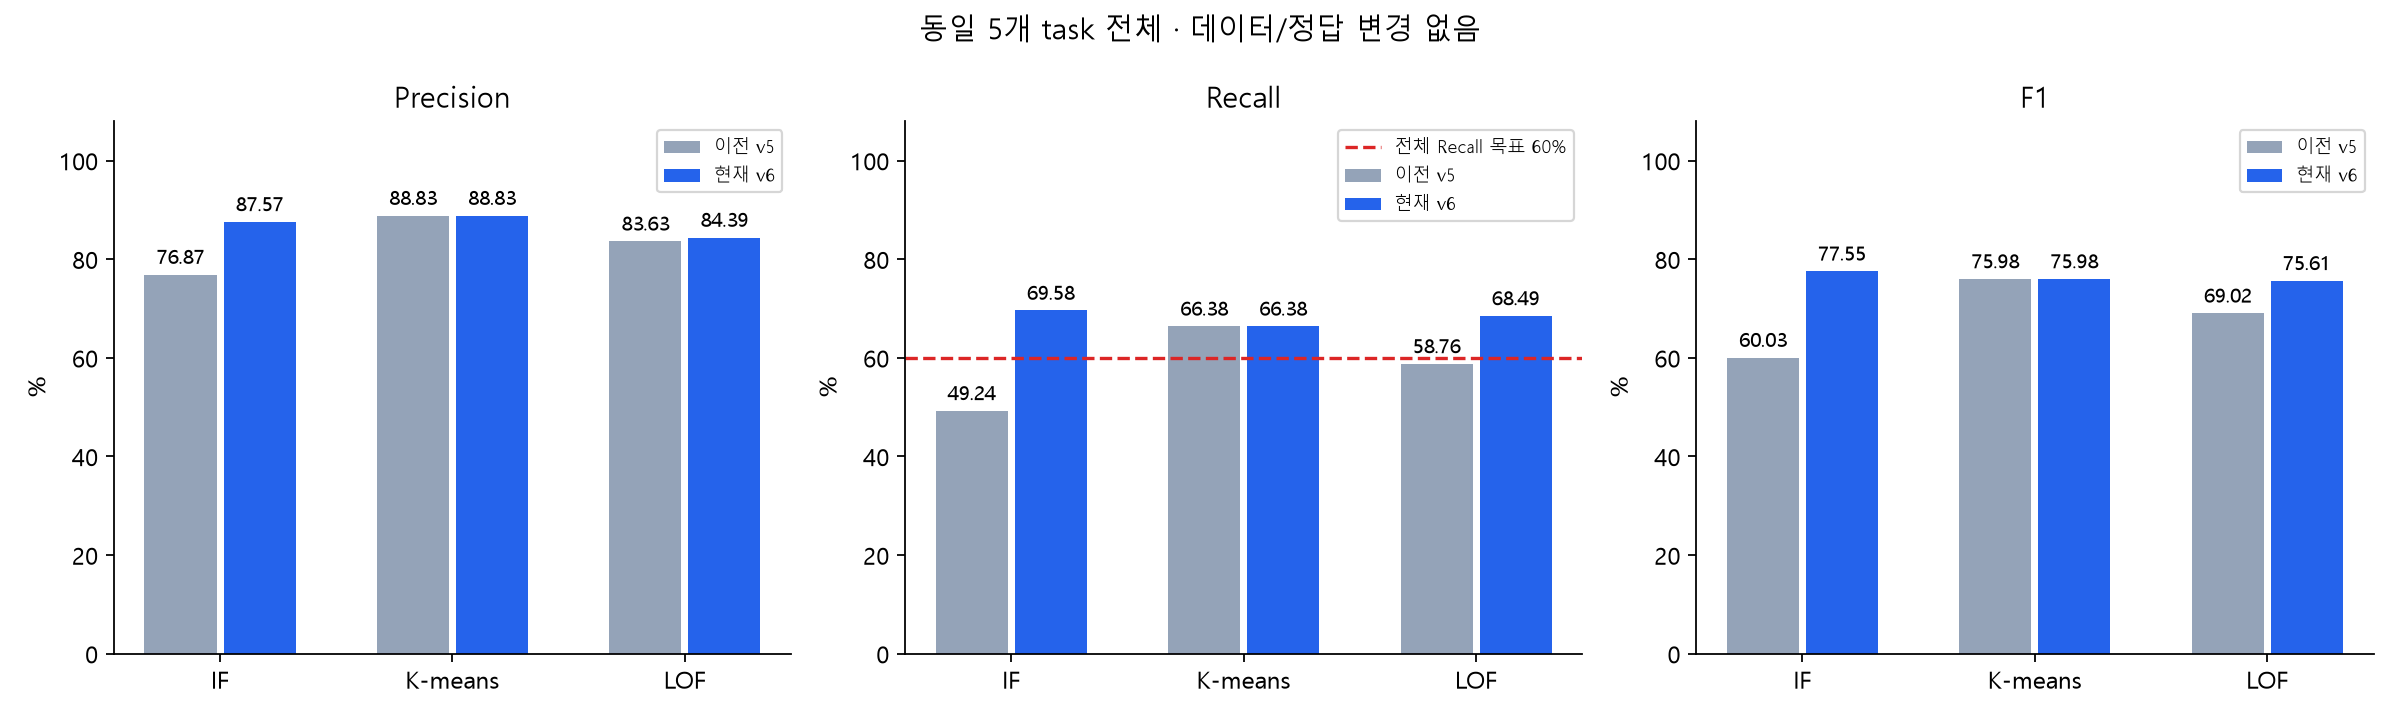

In [2]:
display(metrics(s['pooled']))
changes=[]
for b,r in zip(old['pooled'],s['pooled']):
    row={'model':r['method']}
    for k in keys:row[k+' 전 %']=b[k]*100;row[k+' 후 %']=r[k]*100;row[k+' 차이 %p']=(r[k]-b[k])*100
    changes.append(row)
display(pd.DataFrame(changes).round(2));display(Image(filename=str(LOG/'figures/pooled_comparison.png')))
assert s['all_targets_met']

## 2. task별 F1·Recall·오탐을 함께 보기

**IF의 개별 지연 F1은 64.30% → 52.53%, Recall은 52.17% → 35.79%로 하락했다. 입력 중단 F1도 86.07% → 84.69%로 소폭 하락했다.** 전체 지표 개선을 모든 task 개선이라고 표현하면 안 된다. K-means는 task별 수치도 그대로이고, LOF는 5개 task F1이 모두 v5 이상이다.

범위가 다른 ‘모델 전체 Recall 60%’와 ‘모든 task Recall 60%’를 구분한다. 후자는 미달이다.

,task,method,tp,fp,fn,tn,accuracy,precision,recall,f1,normal_false_positive_rate
0,individual_delay,if,1823,25,3270,54866,0.945069,0.986472,0.357942,0.525285,0.000455
1,individual_delay,kmeans,2366,96,2727,54795,0.952937,0.961007,0.464559,0.626340,0.001749
2,individual_delay,lof,3210,184,1883,54707,0.965541,0.945787,0.630277,0.756451,0.003352
3,group_delay,if,50282,10322,4834,298392,0.958343,0.829681,0.912294,0.869029,0.033435
4,group_delay,kmeans,47743,8808,7373,299906,0.955526,0.844247,0.866228,0.855096,0.028531
5,group_delay,lof,50691,12563,4425,296151,0.953308,0.801388,0.919715,0.856484,0.040695
6,time_burst,if,19623,5217,22040,351976,0.931662,0.789976,0.470993,0.590139,0.014606
7,time_burst,kmeans,20942,3942,20721,353251,0.938166,0.841585,0.502652,0.629390,0.011036
8,time_burst,lof,18340,4408,23323,352785,0.930474,0.806225,0.440199,0.569468,0.012341
9,input_stop,if,61322,3505,18667,418994,0.955876,0.945933,0.766630,0.846895,0.008296


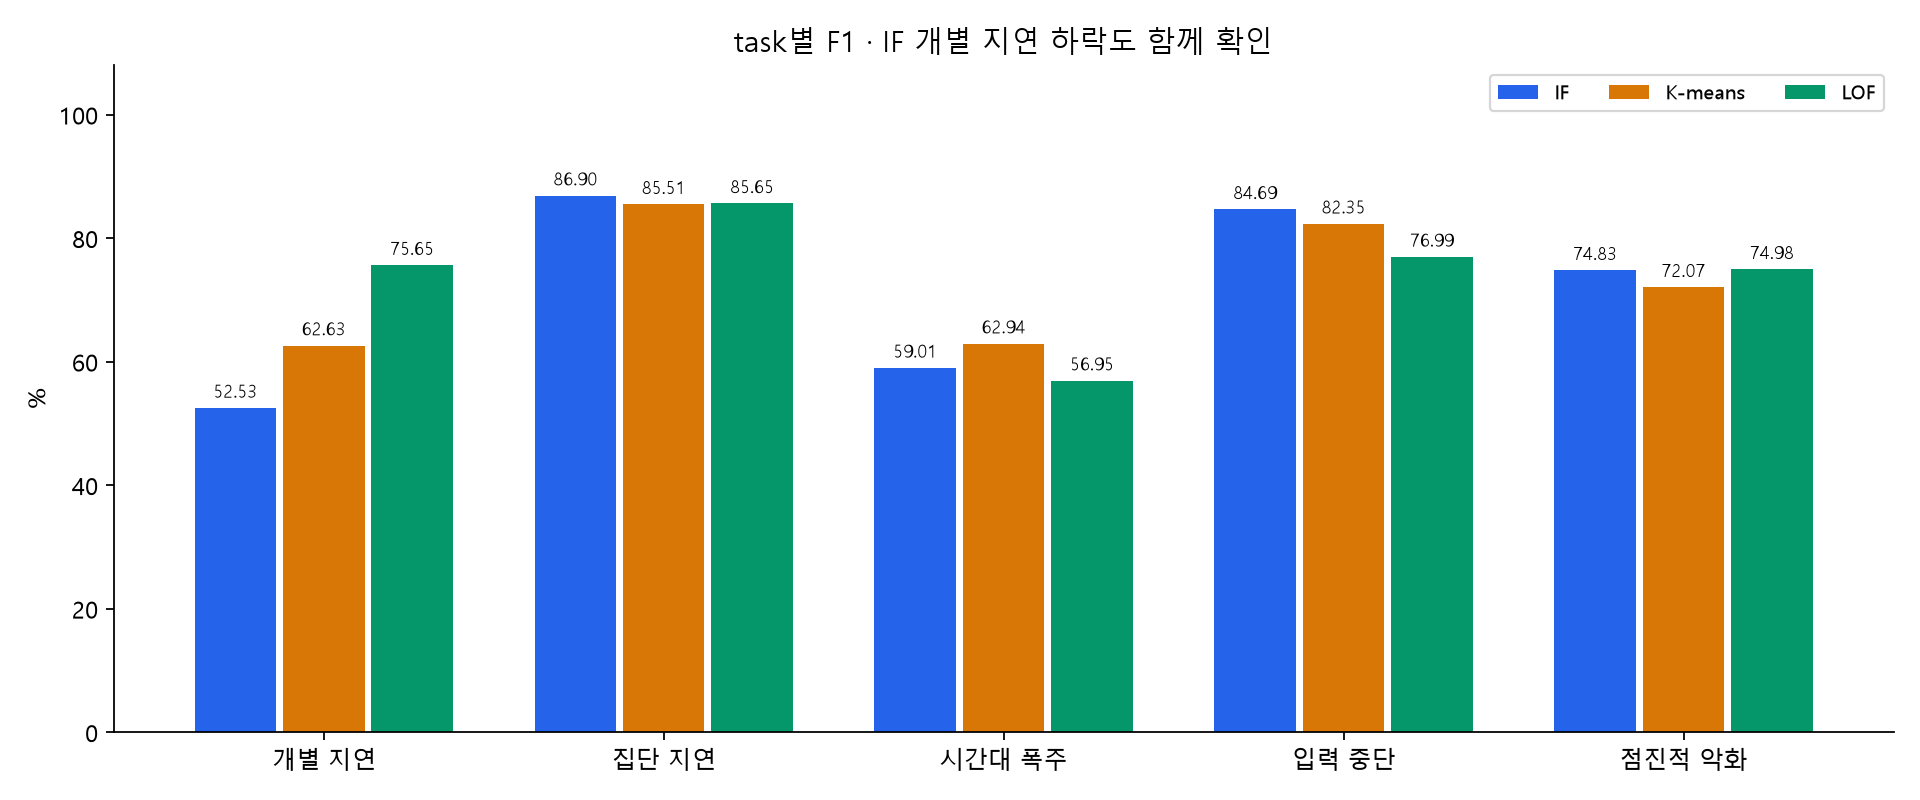

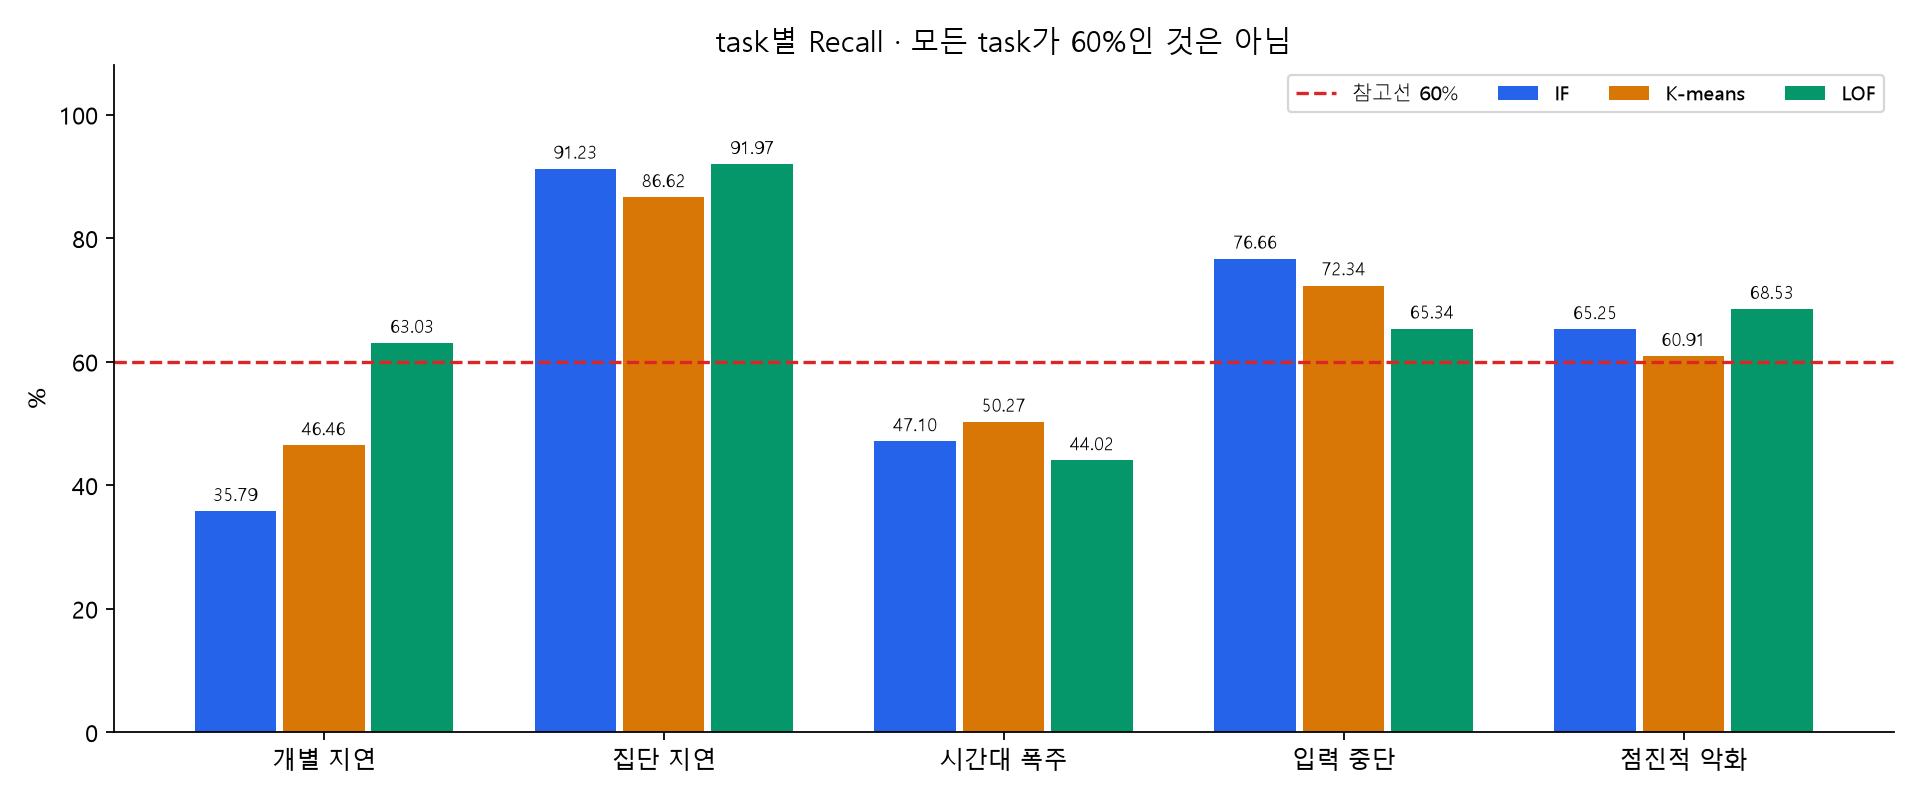

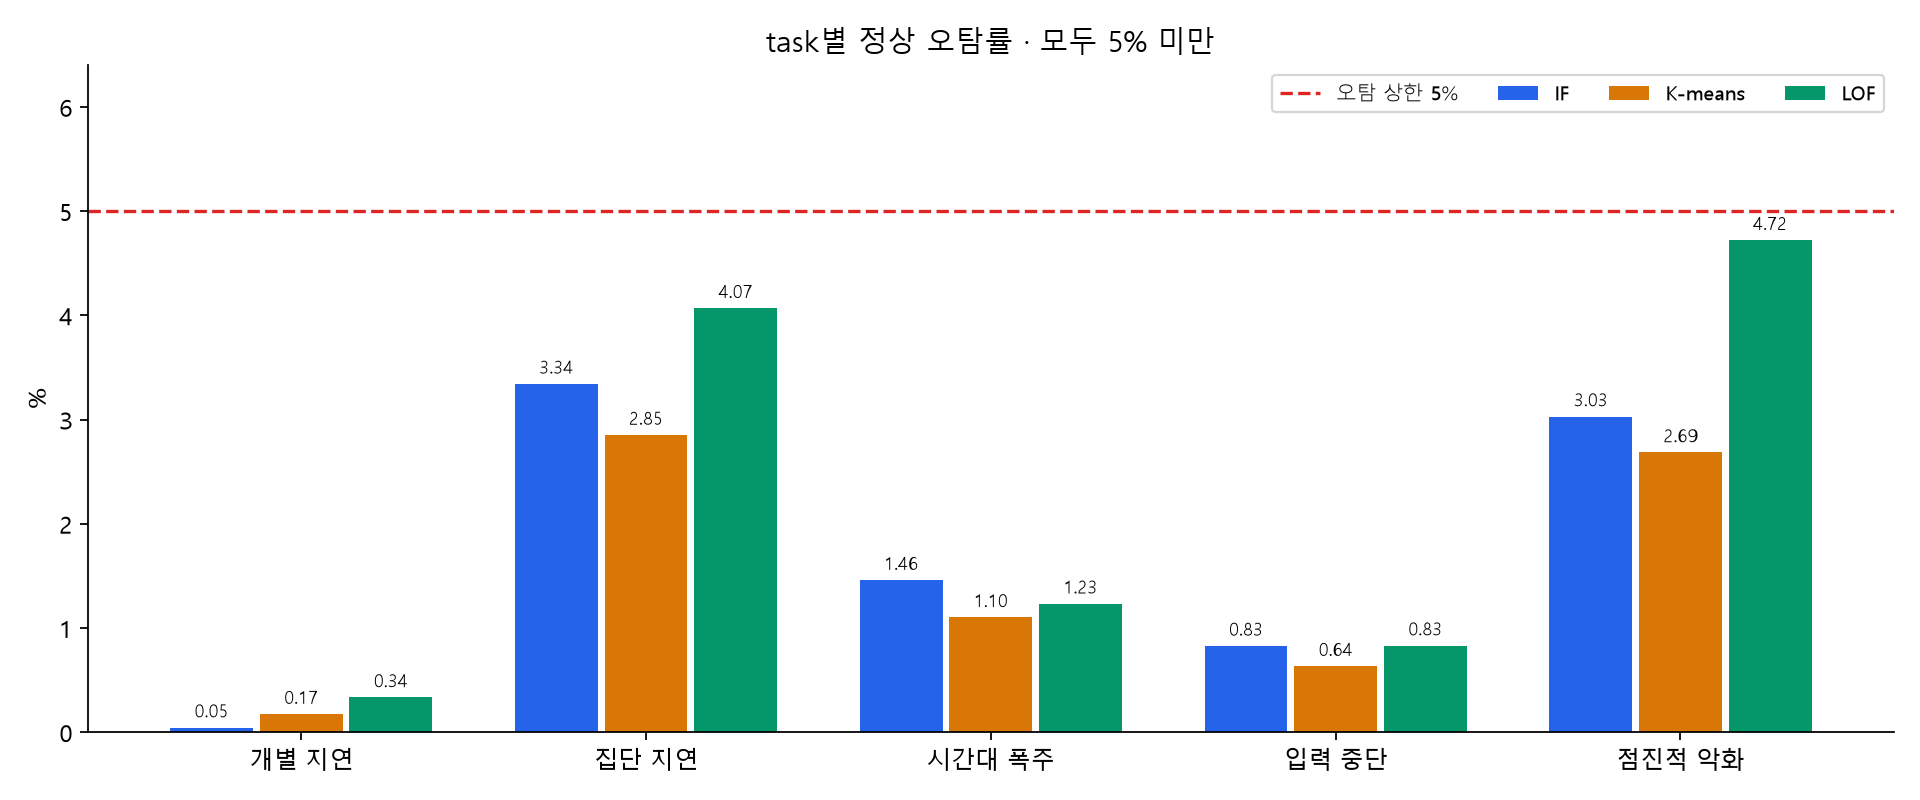

In [3]:
rows=[{'task':d['dataset'],**r}for d in s['datasets']for r in d['metrics']]
table=pd.DataFrame(rows);display(table[['task','method','tp','fp','fn','tn',*keys]].round(6))
for file in ['task_f1.png','task_recall.png','task_fpr.png']:display(Image(filename=str(LOG/'figures'/file)))

## 3. 모델별 장점은 실제 결과로 확인

- **IF:** 집단 지연 F1 **86.90%**, 입력 중단 **84.69%**로 상대적으로 높다. 개별 지연은 약점이다. 집단 지연의 차이는 약 1.25%p로 크지 않다.
- **K-means:** 시간대 폭주 F1 **62.94%**로 가장 높고 최대 task 오탐은 **2.8531%**. 폭주 Recall은 50.27%라 해결 완료가 아니다.
- **LOF:** 개별 지연 F1 **75.65%**로 K-means보다 약 13.01%p 높다. 점진적 악화는 LOF **74.98%**, IF **74.83%**로 사실상 비슷해 LOF만의 독보적 강점으로 부르지 않는다.

아래 간격은 정상/이상 대조를 묶은 **사례 단위 bootstrap 300회**로 계산했다. 모델 선택의 낙관 편향을 제거하거나 실제 운영 성능을 보증하는 구간은 아니다.

In [4]:
roles=read(LOG/'roles.json');display(pd.DataFrame(roles['best_by_task']))
display(pd.DataFrame(roles['pairwise']))

,task,best_F1_model,runner_up,F1_gap_pp,paired_case_bootstrap_95pct_interval_pp,interval_excludes_zero,interpretation
0,individual_delay,lof,kmeans,13.011087,"[12.177903569129564, 13.990248008922439]",True,Conditional sampling uncertainty only; does no...
1,group_delay,if,lof,1.254478,"[0.6792366253365684, 1.9928771345767218]",True,Conditional sampling uncertainty only; does no...
2,time_burst,kmeans,if,3.925096,"[3.6485889247445207, 4.193665737631663]",True,Conditional sampling uncertainty only; does no...
3,input_stop,if,kmeans,2.339191,"[2.2412413063659877, 2.44789379428622]",True,Conditional sampling uncertainty only; does no...
4,gradual_degradation,lof,if,0.153525,"[-0.2360940901357797, 0.5085429916155914]",False,Conditional sampling uncertainty only; does no...


,task,models,prediction_disagreement,alarm_jaccard,anomaly_disagreement
0,individual_delay,"[if, kmeans]",0.011736,0.719186,0.121147
1,individual_delay,"[if, lof]",0.025774,0.544490,0.272335
2,individual_delay,"[kmeans, lof]",0.015537,0.725398,0.165718
3,group_delay,"[if, kmeans]",0.031017,0.824276,0.099082
4,group_delay,"[if, lof]",0.028656,0.844717,0.010142
5,group_delay,"[kmeans, lof]",0.047987,0.745614,0.092714
6,time_burst,"[if, kmeans]",0.012516,0.817531,0.074767
7,time_burst,"[if, lof]",0.010485,0.838439,0.035835
8,time_burst,"[kmeans, lof]",0.011894,0.818848,0.073927
9,input_stop,"[if, kmeans]",0.010104,0.922165,0.047432


## 4. 무엇을 바꿨나 — 신호를 묶고 정상 기준을 맞춤

입력은 기존과 같이 Process 로그에서 만든 1분 피처다. 실행 종류는 **adapterType + processId**, 처리 건수는 **totalCount**, 소요시간은 **endTime−startTime**이다.

새 IF·LOF에서는 이미 계산된 수치 15개를 아래 5개 신호군으로 묶었다. **정상 학습 후보의 중앙값·P95 범위**로 크기를 맞춰 중복된 피처나 크기가 큰 신호가 다른 신호를 가리지 않도록 했다.

| 신호군 | 실제 컬럼 예 | 의미 |
|---|---|---|
| 한 번의 지연 | current_source_upper, current_source_delay | 실행 종류·처리 건수의 정상 후보 참조 대비 현재 소요시간 이탈 |
| 지연 지속 | seq_last_shift, seq_delay_cusum, rank_upper_memory | 최근 지연과 과거 기준 초과가 이어지는 정도 |
| 지연 추세 | rank_duration_cusum, seq_delay_slope, seq_delay_ewma | 소요시간의 누적 변화·증가 경향 |
| 요청 폭주 | traffic_tail_3m/5m, current_prefix_burst | 과거 시간대·초기 관측 대비 최근 실행 횟수 증가 |
| 입력 중단 | gap_expected_prefix, traffic_zero_logprob | 평소 들어오던 실행이 0건인 상태의 지속 |

이는 연속적인 숫자 피처이지 STATUS 규칙이나 새로운 장애 확정 하드 룰이 아니다. 과거 방향으로만 계산하며, 시간대 이력은 현재 합성 정상 이력이라 운영에서는 재검증이 필요하다.

## 5. IF — 정상 대비 가장 큰 신호를 요약해 학습

15개 원천 수치를 정상 기준으로 맞춘 뒤 신호군별 최대를 구하고, 그중 최대인 **요약 피처 1개**를 IF에 입력한다. IF가 15차원 조합을 그대로 학습했다고 말하면 틀리다. 요약 이후 400개 트리, 트리당 max_samples=64로 학습했다.

또한 관측에서 가장 큰 신호군별로 **정상 점수 참조 통계**를 달리해 점수를 보정했다(alpha=0.5, CDF, 5개 참조군). 신호군은 task 정답이 아니라 현재 수치의 argmax로 결정한다. 별도 전문가 IF 5개를 학습한 것이 아니다.

이 구조가 지속 지연·중단을 더 찾도록 했지만 개별 지연의 성능은 낮아졌다. 전체 Recall **69.58%**, F1 **77.55%**, 오탐 **2.05%**.

,실제 IF 설정
settings,"{'algorithm': 'if', 'view': 'radial', 'transfo..."
columns,"[current_source_upper, current_source_delay, s..."
transformed_columns,[evidence_joint_max]
fit_rows,19793
fit_seconds,0.780926
threshold,4.304303
estimator_count,1
adapter_experts,False
normal_only_evidence_scaling,True
hard_rules_added,False


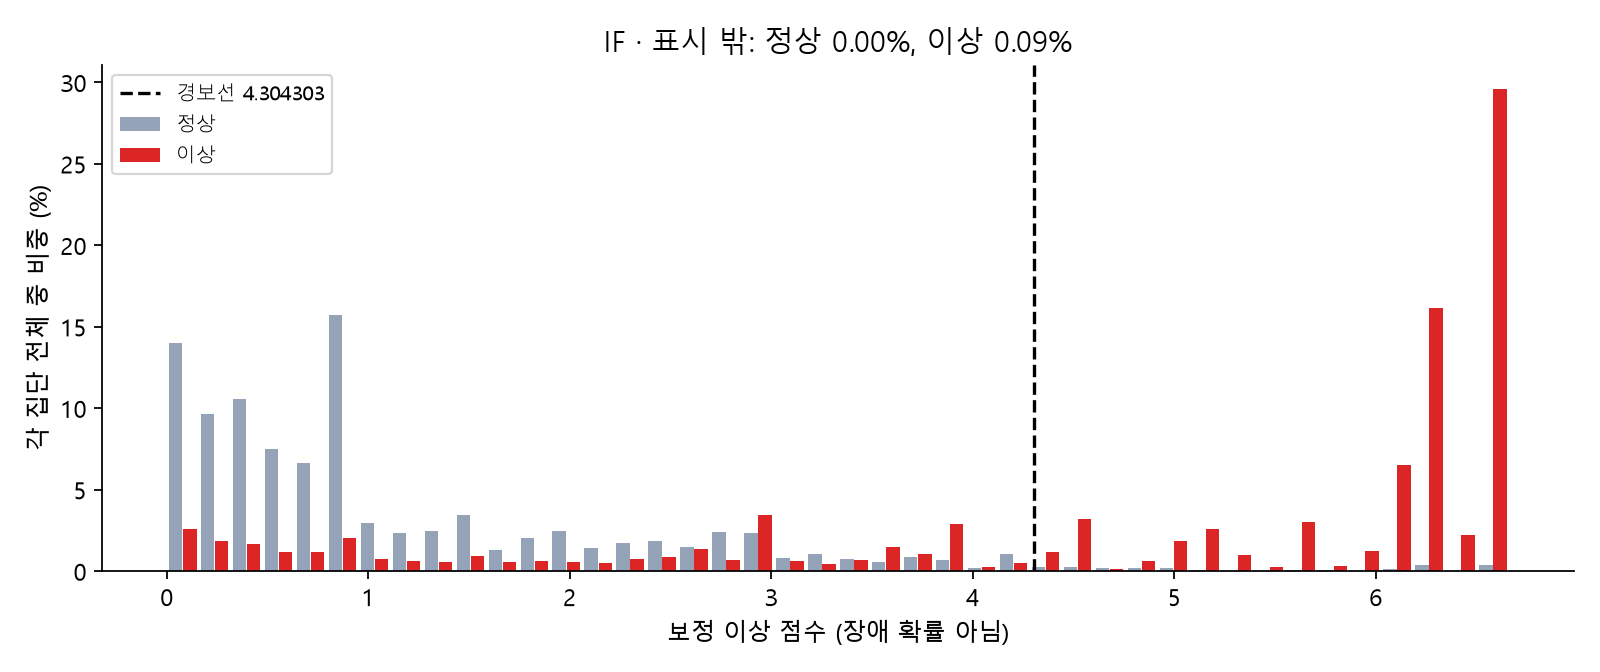

In [5]:
r=sel['models']['if'];display(pd.Series(r).to_frame('실제 IF 설정'));display(Image(filename=str(LOG/'figures/if_threshold.png')))

## 6. K-means — 폭주 강점을 보존하기 위해 유지

새로운 5/11개 요약 피처, 공분산 변환, 군집 수, 신호군별 점수 보정, 기존 19차원에 추가 피처를 붙이는 방식까지 비교했다. 일부 후보는 전체 F1이 약 0.98%p 좋아졌지만 **시간대 폭주 F1이 8.65%p 하락**해 최종 모델로 채택하지 않았다.

현재는 기존 19개 피처·8개 군집·정상 공분산 whitening을 유지한다. 군집 중심까지 거리/정상 P95 반경의 최솟값을 점수로 사용한다. 전체 Recall **66.38%**, F1 **75.98%**, 오탐 **1.73%**. K-means까지 5~10%p 개선했다고 주장하지 않는다.

,실제 K-means 설정
settings,"{'algorithm': 'kmeans', 'view': 'rank', 'adapt..."
columns,"[current_arrival_excess, current_prefix_burst,..."
threshold,5.854851
fit_rows,19793
fit_seconds,0.115787
estimator_count,1
adapter_experts,False
adapter_feature_count,0
causal_context,True
fixed_prefix_completed_observations,6


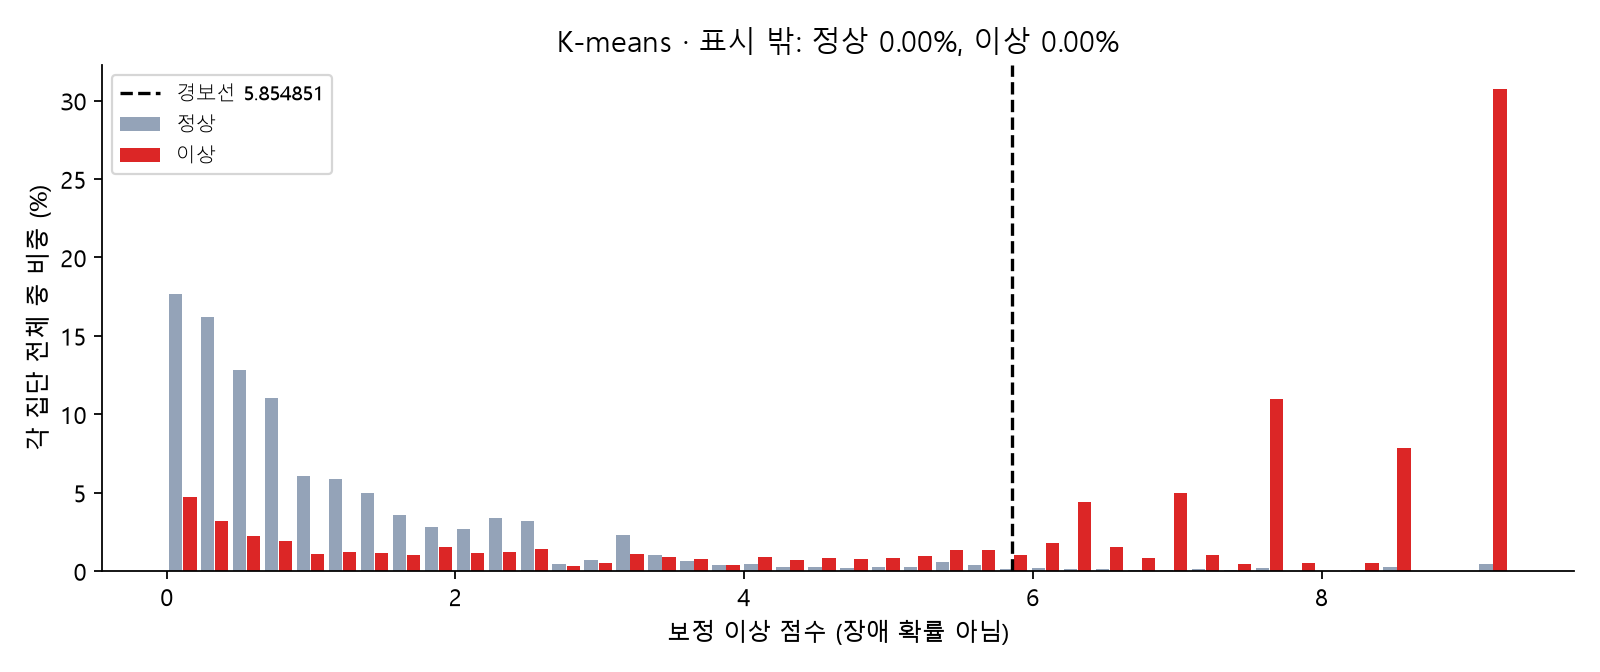

In [6]:
display(pd.Series(sel['models']['kmeans']).to_frame('실제 K-means 설정'));display(Image(filename=str(LOG/'figures/kmeans_threshold.png')))

## 7. LOF — 지연·폭주·중단 신호 11개로 국소 밀도 비교

각 신호군의 최대·평균 10개와 지연 신호 간 동시 상승 1개를 입력한다. 정상 후보에서 가까운 이웃과의 밀도를 비교한다. **11차원**, novelty=True, 이웃 **800개**, 참조점 최대 **4096개**를 사용한다.

관측 가능 상태와 가장 큰 신호군의 조합별 정상 점수 robust 보정(alpha=0.5)을 적용했다. 여러 LOF 전문가나 IF·K-means와의 앙상블이 아니다.

전체 Recall **58.76% → 68.49%**, F1 **69.02% → 75.61%**, Precision **83.63% → 84.39%**. 5개 task F1은 모두 유지·개선됐지만 task별 Precision까지 모두 유지된 것은 아니다. 오탐은 **2.39% → 2.63%**, 최대 task 오탐 **4.7221%**로 상한 이하다.

,실제 LOF 설정
settings,"{'algorithm': 'lof', 'view': 'compact', 'trans..."
columns,"[current_source_upper, current_source_delay, s..."
transformed_columns,"[evidence_point_peak, evidence_point_mean, evi..."
fit_rows,4096
fit_seconds,0.544995
threshold,3.791602
estimator_count,1
adapter_experts,False
normal_only_evidence_scaling,True
hard_rules_added,False


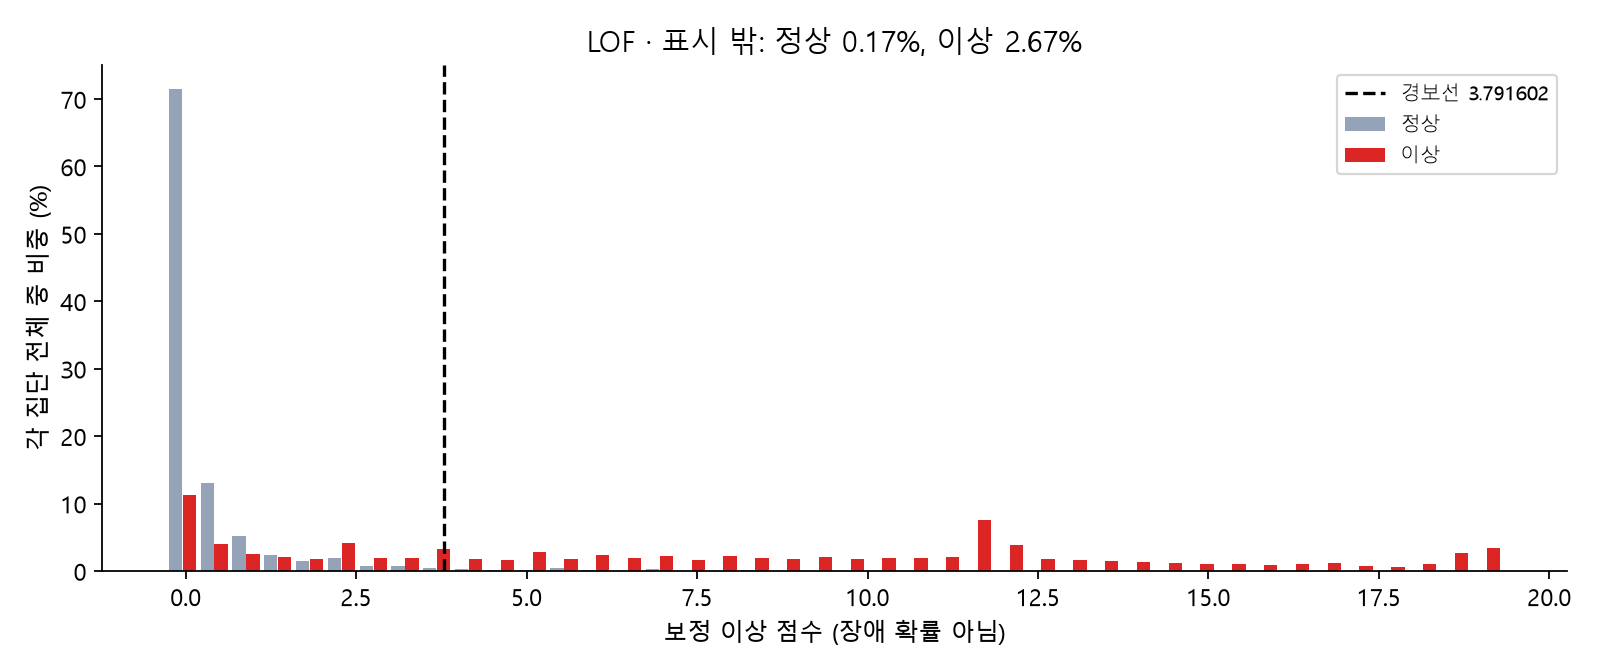

In [7]:
display(pd.Series(sel['models']['lof']).to_frame('실제 LOF 설정'));display(Image(filename=str(LOG/'figures/lof_threshold.png')))

## 8. 학습·선택·평가 경계와 한계

- 정상 후보 **19,793개 분**으로 추정기를 fit하고 별도 정상 **17,925개 분**으로 점수·경보선을 보정했다. LOF는 중복 제거 후 최대 4096개 참조점만 사용한다. **S는 성능 정상 보장이 아니다.**
- 개발용 정답으로 후보를 비교했고, 이미 반복 사용한 연구 벤치마크에서 **task별 200개 전체 사례 + 정상 대조군**을 예비 비교에 썼다. 채택 후보를 고정한 뒤 전체 5000개 사례씩 평가했다. **일부 평가 정답이 후보·경보 정책 선택에 쓰였으므로 외부 블라인드 테스트가 아니다.**
- 경보선 후보는 별도 정상 점수 분위수에서 계산했지만 최종 채택에는 재사용 연구 평가 결과를 확인했다. 데이터·정답·난이도·point adjustment로 점수를 올리지 않았다.
- 정상 분위수나 bootstrap 구간은 운영 오탐률 보장이 아니다. 외부 운영 로그와 장애로 재검증해야 한다.
- [COPOD 논문](https://arxiv.org/abs/2009.09463)의 경험적 꼬리 확률 관점도 검토했다. 피처 ECDF 후보를 실험했으나 현재 IF·LOF의 원천 피처 스케일링은 robust 방식이다. 정상 점수 CDF 보정은 사용하지만 COPOD 자체를 구현·채택한 것은 아니다.
- [scikit-learn 공식 문서](https://scikit-learn.org/stable/modules/outlier_detection.html)에 따라 LOF는 novelty=True로 설정해 학습 참조점과 별도의 관측을 평가한다.

## 9. 검증과 백엔드 전달

독립 지표 재계산·원시 Process 입력·저장/로드 점수 일치·미지 Adapter fallback·과거 판정 인과성 및 **79개 테스트**를 확인했다. 새 피처는 미래 로그로 이전 값을 바꾸지 않는다.

현재 전달용 파일은 **reports/shared_model_v6/release/handoff/{if,kmeans,lof}_shared.joblib**와 manifest.json이다. 이전 v5를 덮어쓰지 않았다. 의존 code 모듈도 필요하다. worker의 빈 1분 생성·이전 상태 보관·지연 도착 처리·실제 배포는 별도 작업이다. 이 작업에서는 Git push나 Notion 페이지 수정은 하지 않았다.

In [8]:
audit=read(LOG/'audit.json');display({k:v for k,v in audit.items()if k!='raw_serving_checks'})
display(pd.DataFrame([{'model':r['algorithm'],'file':r['file'],'bytes':r['bytes'],'threshold':r['threshold'],'raw Process':r['raw_Process_predict'],'prefix causal':r['prefix_causal']}for r in handoff['models']]))
for r in handoff['models']:
    display(Markdown('### '+r['algorithm']+' 실제 원천/변환 피처'))
    display(pd.Series(r['columns'],name='원천 피처').to_frame())
    if 'transformed_columns'in r:display(pd.Series(r['transformed_columns'],name='추정기에 들어가는 변환 피처').to_frame())

{'checks_passed': True,
 'all_targets_met': True,
 'unit_tests_run': 79,
 'unit_tests_passed': True,
 'independent_confusion_counts': True,
 'remaining_data_labels_unchanged': True,
 'ADBench_unchanged': True,
 'model_sha256': '0b733a72299a514f30c296472e78e337f307a0e3d13913e7153f9a81504e730a',
 'summary_sha256': '75852e055c83319b98e70a3f8397f252e2be3c11383c365308533bb525a31002',
 'external_blind_test': False,
 'Recall_60pct_scope': 'each model pooled, NOT every task',
 'pooled_accuracy_precision_F1_nonregression_verified': True,
 'all_task_FPR_at_most_5pct_verified': True,
 'all_task_F1_nonregression': {'if': False, 'kmeans': True, 'lof': True},
 'independent_sklearn_metrics_recomputation': True,
 'normal_geometry_KDTree_query_counters_not_learned_parameters': True,
 'unchanged_active_benchmark_and_ADBench': True,
 'no_data_label_severity_change': True}

,model,file,bytes,threshold,raw Process,prefix causal
0,if,if_shared.joblib,589371,4.304303,True,True
1,kmeans,kmeans_shared.joblib,343338,5.854851,True,True
2,lof,lof_shared.joblib,11605609,3.791602,True,True


### if 실제 원천/변환 피처

,원천 피처
0,current_source_upper
1,current_source_delay
2,seq_last_shift
3,seq_delay_cusum
4,rank_upper_memory
5,rank_duration_cusum
6,seq_delay_slope
7,seq_delay_ewma
8,traffic_tail_3m
9,traffic_tail_5m


,추정기에 들어가는 변환 피처
0,evidence_joint_max


### kmeans 실제 원천/변환 피처

,원천 피처
0,current_arrival_excess
1,current_prefix_burst
2,gap_expected_prefix
3,gap_expected_recent
4,empty_expected_rate
5,current_source_upper
6,current_source_lower
7,rank_upper_run
8,rank_lower_run
9,rank_upper_memory


### lof 실제 원천/변환 피처

,원천 피처
0,current_source_upper
1,current_source_delay
2,seq_last_shift
3,seq_delay_cusum
4,rank_upper_memory
5,rank_duration_cusum
6,seq_delay_slope
7,seq_delay_ewma
8,traffic_tail_3m
9,traffic_tail_5m


,추정기에 들어가는 변환 피처
0,evidence_point_peak
1,evidence_point_mean
2,evidence_delay_peak
3,evidence_delay_mean
4,evidence_trend_peak
5,evidence_trend_mean
6,evidence_burst_peak
7,evidence_burst_mean
8,evidence_gap_peak
9,evidence_gap_mean
